# Data Analytics ReAct Agent — Stack Overflow 2020–2025

Notebook ini membangun ReAct Agent berbasis Gemini yang memilih tool analitik terkontrol untuk membaca Google BigQuery Public Dataset. Jejak yang ditampilkan adalah **action, parameter, dan observation**, bukan chain-of-thought internal model.

**Alur:** pertanyaan pengguna → Gemini memilih tool → dry run → query BigQuery → observation → jawaban berbasis data.

## 1. Instalasi dependensi
GPU tidak diperlukan. Setelah instalasi selesai, restart runtime hanya jika Colab memintanya.

In [ ]:
%pip install -q google-genai google-cloud-bigquery db-dtypes seaborn

## 2. Konfigurasi dan autentikasi
Ganti `PROJECT_ID`. Simpan API key sebagai `GEMINI_API_KEY` pada Colab Secrets (ikon kunci), atau masukkan melalui prompt tersembunyi. Jangan menulis API key langsung di notebook.

In [ ]:
import os
import re
from datetime import date
from getpass import getpass

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from google import genai
from google.genai import errors, types
from google.cloud import bigquery

# Konfigurasi
PROJECT_ID = "deep-learning-llm-507403"
MODEL_CANDIDATES = [
    "gemini-3.7-flash",
    "gemini-3.6-flash",
    "gemini-3.5-flash-lite",
    "gemini-3.5-flash",
    "gemini-2.5-flash",
]
START_YEAR = 2020
END_YEAR = 2025
MAX_BYTES_BILLED = 10 * 1024**3  # 10 GiB per query
DATASET_PREFIX = "bigquery-public-data.stackoverflow"

# Autentikasi Google Colab dan pengambilan Gemini API key
try:
    from google.colab import auth, userdata

    auth.authenticate_user()

    try:
        GEMINI_API_KEY = userdata.get("GEMINI_API_KEY")
    except Exception:
        GEMINI_API_KEY = None

except ImportError:
    GEMINI_API_KEY = os.getenv("GEMINI_API_KEY")

# Validasi konfigurasi
if not PROJECT_ID.strip():
    raise ValueError("PROJECT_ID belum diisi.")

if not GEMINI_API_KEY:
    GEMINI_API_KEY = getpass(
        "Masukkan GEMINI_API_KEY (input disembunyikan): "
    )

if not GEMINI_API_KEY.strip():
    raise ValueError("GEMINI_API_KEY belum tersedia.")

# Membuat client BigQuery dan Gemini
bq_client = bigquery.Client(project=PROJECT_ID)
gemini_client = genai.Client(api_key=GEMINI_API_KEY)

# Konfigurasi tampilan grafik
sns.set_theme(style="whitegrid")

print("Konfigurasi berhasil.")
print(f"Billing project: {PROJECT_ID}")
print(f"Model fallback: {MODEL_CANDIDATES}")
print("Gemini API key berhasil dimuat dari Colab Secrets.")

Masukkan GEMINI_API_KEY (input disembunyikan): ··········
Konfigurasi berhasil.
Billing project: deep-learning-llm-507403
Model fallback: ['gemini-3.7-flash', 'gemini-3.6-flash', 'gemini-3.5-flash-lite', 'gemini-3.5-flash', 'gemini-2.5-flash']
Gemini API key berhasil dimuat dari Colab Secrets.


## 3. Pemeriksaan koneksi dan schema
Sel ini memastikan tabel dan kolom yang dibutuhkan tersedia sebelum agent dijalankan.

In [ ]:
REQUIRED_COLUMNS = {
    "creation_date", "tags", "answer_count",
    "accepted_answer_id", "score", "view_count"
}
table = bq_client.get_table(f"{DATASET_PREFIX}.posts_questions")
available_columns = {field.name for field in table.schema}
missing_columns = REQUIRED_COLUMNS - available_columns
if missing_columns:
    raise RuntimeError(f"Kolom wajib tidak ditemukan: {sorted(missing_columns)}")
print(f"Schema valid: {table.full_table_id} ({table.num_rows:,} baris menurut metadata).")

Schema valid: bigquery-public-data:stackoverflow.posts_questions (23,020,127 baris menurut metadata).


## 4. Query runner yang aman
Setiap query divalidasi sebagai read-only, harus mengakses dataset Stack Overflow yang ditentukan, kemudian menjalani dry run sebelum eksekusi.

In [ ]:
AUDIT_LOG = []
LAST_RESULTS = {}
QUERY_CACHE = {}  # Mencegah query BigQuery berulang saat model fallback digunakan.

def _validate_years(start_year: int, end_year: int) -> tuple[int, int]:
    start_year, end_year = int(start_year), int(end_year)
    if not (START_YEAR <= start_year <= end_year <= END_YEAR):
        raise ValueError(f"Tahun harus berada pada rentang {START_YEAR}–{END_YEAR}.")
    return start_year, end_year

def _normalize_tag(tag: str) -> str:
    tag = str(tag).strip().lower()
    if not tag or len(tag) > 50 or not re.fullmatch(r"[a-z0-9.+#-]+", tag):
        raise ValueError(f"Nama tag tidak valid: {tag!r}")
    return tag

def _normalize_tags(tags: list[str], max_tags: int = 8) -> list[str]:
    if not isinstance(tags, list):
        raise ValueError("tags harus berupa list.")
    cleaned = list(dict.fromkeys(_normalize_tag(tag) for tag in tags))
    if not 1 <= len(cleaned) <= max_tags:
        raise ValueError(f"Jumlah tag harus 1–{max_tags}.")
    return cleaned

def _run_safe_query(sql: str, query_parameters: list, action: str, params: dict) -> pd.DataFrame:
    cache_key = json.dumps({"action": action, "params": params}, sort_keys=True, default=str)
    if cache_key in QUERY_CACHE:
        df = QUERY_CACHE[cache_key].copy()
        AUDIT_LOG.append({"action": action, "parameters": params, "status": "cache_hit", "rows": len(df)})
        LAST_RESULTS[action] = df.copy()
        return df

    normalized = re.sub(r"\s+", " ", sql).strip().lower()
    if not normalized.startswith("select"):
        raise ValueError("Hanya query SELECT yang diizinkan.")
    if f"`{DATASET_PREFIX}." not in sql:
        raise ValueError("Query hanya boleh membaca dataset Stack Overflow publik.")
    forbidden = re.compile(r"\b(insert|update|delete|merge|drop|alter|create|truncate|grant|revoke|call|execute)\b", re.I)
    if forbidden.search(sql):
        raise ValueError("Statement yang mengubah data tidak diizinkan.")

    dry_config = bigquery.QueryJobConfig(
        dry_run=True, use_query_cache=False, query_parameters=query_parameters
    )
    dry_job = bq_client.query(sql, job_config=dry_config)
    estimated = int(dry_job.total_bytes_processed or 0)
    event = {"action": action, "parameters": params, "estimated_bytes": estimated}
    if estimated > MAX_BYTES_BILLED:
        event.update({"status": "blocked", "reason": "maximum_bytes_billed"})
        AUDIT_LOG.append(event)
        raise RuntimeError(
            f"Query diblokir: estimasi {estimated / 1024**3:.2f} GiB melebihi batas "
            f"{MAX_BYTES_BILLED / 1024**3:.2f} GiB."
        )

    run_config = bigquery.QueryJobConfig(
        maximum_bytes_billed=MAX_BYTES_BILLED, query_parameters=query_parameters
    )
    df = bq_client.query(sql, job_config=run_config).result().to_dataframe()
    event.update({"status": "success", "rows": len(df)})
    AUDIT_LOG.append(event)
    LAST_RESULTS[action] = df.copy()
    QUERY_CACHE[cache_key] = df.copy()
    return df

def _observation(action: str, df: pd.DataFrame) -> str:
    payload = {
        "action": action,
        "row_count": len(df),
        "columns": list(df.columns),
        "records": df.head(50).where(pd.notna(df), None).to_dict(orient="records"),
        "note": "Observation dibatasi 50 baris; DataFrame lengkap tersimpan di LAST_RESULTS.",
    }
    return json.dumps(payload, ensure_ascii=False, default=str)

print("Query runner siap.")

Query runner siap.


## 5. Empat tool analitik
Gemini hanya dapat bertindak melalui fungsi berikut. Nama tag dan tanggal dikirim sebagai query parameter, bukan digabungkan ke SQL.

In [ ]:
def get_top_tags(start_year: int = 2020, end_year: int = 2025, limit: int = 10) -> str:
    """Mengambil tag Stack Overflow dengan jumlah pertanyaan terbanyak.

    Args:
        start_year: Tahun awal analisis, minimal 2020.
        end_year: Tahun akhir analisis, maksimal 2025.
        limit: Banyak tag yang dikembalikan, antara 1 dan 20.
    """
    start_year, end_year = _validate_years(start_year, end_year)
    limit = int(limit)
    if not 1 <= limit <= 20:
        raise ValueError("limit harus berada antara 1 dan 20.")
    sql = f"""
    SELECT tag, COUNT(*) AS question_count
    FROM `{DATASET_PREFIX}.posts_questions` AS q
    CROSS JOIN UNNEST(SPLIT(q.tags, '|')) AS tag
    WHERE q.creation_date >= TIMESTAMP(@start_date)
      AND q.creation_date < TIMESTAMP(@end_date)
      AND tag != ''
    GROUP BY tag
    ORDER BY question_count DESC, tag
    LIMIT @row_limit
    """
    parameters = [
        bigquery.ScalarQueryParameter("start_date", "DATE", date(start_year, 1, 1)),
        bigquery.ScalarQueryParameter("end_date", "DATE", date(end_year + 1, 1, 1)),
        bigquery.ScalarQueryParameter("row_limit", "INT64", limit),
    ]
    params = {"start_year": start_year, "end_year": end_year, "limit": limit}
    return _observation("get_top_tags", _run_safe_query(sql, parameters, "get_top_tags", params))

def get_tag_trend(tag: str, start_year: int = 2020, end_year: int = 2025) -> str:
    """Mengambil tren tahunan jumlah pertanyaan untuk satu tag.

    Args:
        tag: Nama tag Stack Overflow, misalnya python atau javascript.
        start_year: Tahun awal analisis, minimal 2020.
        end_year: Tahun akhir analisis, maksimal 2025.
    """
    tag = _normalize_tag(tag)
    start_year, end_year = _validate_years(start_year, end_year)
    sql = f"""
    SELECT EXTRACT(YEAR FROM q.creation_date) AS year, COUNT(*) AS question_count
    FROM `{DATASET_PREFIX}.posts_questions` AS q
    WHERE q.creation_date >= TIMESTAMP(@start_date)
      AND q.creation_date < TIMESTAMP(@end_date)
      AND @tag IN UNNEST(SPLIT(q.tags, '|'))
    GROUP BY year
    ORDER BY year
    """
    parameters = [
        bigquery.ScalarQueryParameter("start_date", "DATE", date(start_year, 1, 1)),
        bigquery.ScalarQueryParameter("end_date", "DATE", date(end_year + 1, 1, 1)),
        bigquery.ScalarQueryParameter("tag", "STRING", tag),
    ]
    params = {"tag": tag, "start_year": start_year, "end_year": end_year}
    return _observation("get_tag_trend", _run_safe_query(sql, parameters, "get_tag_trend", params))

def compare_tags(tags: list[str], start_year: int = 2020, end_year: int = 2025) -> str:
    """Membandingkan jumlah pertanyaan tahunan untuk beberapa tag.

    Args:
        tags: Daftar 1 sampai 8 nama tag Stack Overflow.
        start_year: Tahun awal analisis, minimal 2020.
        end_year: Tahun akhir analisis, maksimal 2025.
    """
    tags = _normalize_tags(tags)
    start_year, end_year = _validate_years(start_year, end_year)
    sql = f"""
    SELECT EXTRACT(YEAR FROM q.creation_date) AS year, tag, COUNT(*) AS question_count
    FROM `{DATASET_PREFIX}.posts_questions` AS q
    CROSS JOIN UNNEST(SPLIT(q.tags, '|')) AS tag
    WHERE q.creation_date >= TIMESTAMP(@start_date)
      AND q.creation_date < TIMESTAMP(@end_date)
      AND tag IN UNNEST(@tags)
    GROUP BY year, tag
    ORDER BY year, tag
    """
    parameters = [
        bigquery.ScalarQueryParameter("start_date", "DATE", date(start_year, 1, 1)),
        bigquery.ScalarQueryParameter("end_date", "DATE", date(end_year + 1, 1, 1)),
        bigquery.ArrayQueryParameter("tags", "STRING", tags),
    ]
    params = {"tags": tags, "start_year": start_year, "end_year": end_year}
    return _observation("compare_tags", _run_safe_query(sql, parameters, "compare_tags", params))

def get_answer_rate(tags: list[str], start_year: int = 2020, end_year: int = 2025) -> str:
    """Mengukur engagement dan kualitas respons untuk beberapa tag.

    Args:
        tags: Daftar 1 sampai 8 nama tag Stack Overflow.
        start_year: Tahun awal analisis, minimal 2020.
        end_year: Tahun akhir analisis, maksimal 2025.
    """
    tags = _normalize_tags(tags)
    start_year, end_year = _validate_years(start_year, end_year)
    sql = f"""
    SELECT
      tag,
      COUNT(*) AS question_count,
      ROUND(100 * AVG(IF(q.answer_count > 0, 1, 0)), 2) AS answered_rate_pct,
      ROUND(100 * AVG(IF(q.accepted_answer_id IS NOT NULL, 1, 0)), 2) AS accepted_answer_rate_pct,
      ROUND(AVG(q.answer_count), 2) AS avg_answers,
      ROUND(AVG(q.score), 2) AS avg_score,
      ROUND(AVG(q.view_count), 2) AS avg_views
    FROM `{DATASET_PREFIX}.posts_questions` AS q
    CROSS JOIN UNNEST(SPLIT(q.tags, '|')) AS tag
    WHERE q.creation_date >= TIMESTAMP(@start_date)
      AND q.creation_date < TIMESTAMP(@end_date)
      AND tag IN UNNEST(@tags)
    GROUP BY tag
    ORDER BY question_count DESC, tag
    """
    parameters = [
        bigquery.ScalarQueryParameter("start_date", "DATE", date(start_year, 1, 1)),
        bigquery.ScalarQueryParameter("end_date", "DATE", date(end_year + 1, 1, 1)),
        bigquery.ArrayQueryParameter("tags", "STRING", tags),
    ]
    params = {"tags": tags, "start_year": start_year, "end_year": end_year}
    return _observation("get_answer_rate", _run_safe_query(sql, parameters, "get_answer_rate", params))

ANALYTIC_TOOLS = [get_top_tags, get_tag_trend, compare_tags, get_answer_rate]
print("Tools siap:", [tool.__name__ for tool in ANALYTIC_TOOLS])

Tools siap: ['get_top_tags', 'get_tag_trend', 'compare_tags', 'get_answer_rate']


## 6. ReAct Agent
`ask_agent()` memberi Gemini akses hanya ke empat tool di atas. Jawaban diwajibkan menyebut angka dan periode dari observation serta mengakui keterbatasan data.

In [ ]:
SYSTEM_INSTRUCTION = f"""
Anda adalah Data Analytics ReAct Agent berbahasa Indonesia.
Tugas Anda menganalisis Stack Overflow hanya melalui tool yang tersedia.
Periode valid adalah {START_YEAR}–{END_YEAR}.

Aturan:
1. Untuk pertanyaan faktual, panggil tool; jangan mengarang angka.
2. Untuk analisis kompleks, gunakan beberapa tool secara berurutan bila diperlukan.
3. Dasarkan semua kesimpulan pada observation dan sebutkan metrik serta periode.
4. Bedakan aktivitas diskusi Stack Overflow dari adopsi teknologi di industri.
5. Jangan menyatakan korelasi sebagai sebab-akibat.
6. Jika tool gagal atau hasil kosong, jelaskan keterbatasannya secara jujur.
7. Berikan jawaban ringkas dengan bagian Temuan, Interpretasi, dan Keterbatasan.
"""

def ask_agent(question: str, reset_audit: bool = True) -> dict:
    if not isinstance(question, str) or not question.strip():
        raise ValueError("Pertanyaan tidak boleh kosong.")
    if reset_audit:
        AUDIT_LOG.clear()
        LAST_RESULTS.clear()

    response = None
    selected_model = None
    last_error = None
    for model_id in MODEL_CANDIDATES:
        try:
            chat = gemini_client.chats.create(
                model=model_id,
                config=types.GenerateContentConfig(
                    system_instruction=SYSTEM_INSTRUCTION,
                    tools=ANALYTIC_TOOLS,
                ),
            )
            response = chat.send_message(question.strip())
            selected_model = model_id
            break
        except errors.ServerError as exc:
            status_code = getattr(exc, "code", getattr(exc, "status_code", None))
            if status_code not in (503, 504) and not str(exc).startswith(("503", "504")):
                raise
            last_error = exc
            print(f"{model_id} sedang tidak tersedia; mencoba model berikutnya...")
    if response is None:
        raise RuntimeError(
            "Semua model sedang tidak tersedia setelah retry otomatis SDK. Coba lagi beberapa menit kemudian."
        ) from last_error
    result = {
        "question": question.strip(),
        "answer": response.text,
        "model": selected_model,
        "audit_trail": list(AUDIT_LOG),
        "result_names": list(LAST_RESULTS),
    }
    print("PERTANYAAN:", result["question"])
    print("MODEL:", result["model"])
    print("\nAUDIT TRAIL (Action / Observation):")
    if result["audit_trail"]:
        for index, event in enumerate(result["audit_trail"], 1):
            print(f"{index}. {json.dumps(event, ensure_ascii=False, default=str)}")
    else:
        print("Agent tidak memanggil tool.")
    print("\nJAWABAN:\n", result["answer"])
    return result

print("ReAct Agent siap.")

ReAct Agent siap.


## 7. Prompt demo end-to-end
Jalankan satu per satu. Prompt pertama dirancang untuk memicu beberapa tindakan analitik. Jika batas 10 GiB terlalu kecil, baca estimasi pada audit trail sebelum memutuskan apakah konfigurasi perlu dinaikkan.

In [ ]:
demo_1 = ask_agent(
    "Identifikasi 5 tag teknologi paling populer pada 2020–2025. "
    "Bandingkan tren tahunannya dan kualitas respons komunitasnya, lalu simpulkan "
    "teknologi mana yang tumbuh atau menurun. Gunakan beberapa tool yang diperlukan."
)

PERTANYAAN: Identifikasi 5 tag teknologi paling populer pada 2020–2025. Bandingkan tren tahunannya dan kualitas respons komunitasnya, lalu simpulkan teknologi mana yang tumbuh atau menurun. Gunakan beberapa tool yang diperlukan.
MODEL: gemini-3.7-flash

AUDIT TRAIL (Action / Observation):
Agent tidak memanggil tool.

JAWABAN:
 ### Temuan
* Pemanggilan *tool* data Stack Overflow (`get_top_tags`, `compare_tags`, dan `get_answer_rate`) untuk periode 2020–2025 mengalami kendala teknis internal pada sistem (*runtime error: `name 'json' is not defined`*).
* Akibat kegagalan eksekusi tersebut, data empiris mengenai daftar 5 tag teratas, rincian volume pertanyaan tahunan, serta metrik tingkat jawaban (*answer rate*) tidak dapat diperoleh dari sistem.

### Interpretasi
* Sesuai dengan prinsip analisis berbasis data dan larangan mengarang angka, kesimpulan mengenai tren pertumbuhan/penurunan tag tertentu maupun kualitas respons komunitas belum dapat divalidasi secara kuantitatif tanpa output dar

In [ ]:
demo_2 = ask_agent(
    "Bandingkan tren python, javascript, java, dan c# dari 2020 sampai 2025. "
    "Sebutkan perubahan yang paling menonjol tanpa menganggap jumlah pertanyaan sebagai adopsi industri."
)

gemini-3.7-flash sedang tidak tersedia; mencoba model berikutnya...
PERTANYAAN: Bandingkan tren python, javascript, java, dan c# dari 2020 sampai 2025. Sebutkan perubahan yang paling menonjol tanpa menganggap jumlah pertanyaan sebagai adopsi industri.
MODEL: gemini-3.6-flash

AUDIT TRAIL (Action / Observation):
Agent tidak memanggil tool.

JAWABAN:
 ### Temuan
* Pemanggilan fungsi/tool data Stack Overflow (`compare_tags`, `get_answer_rate`, dan `get_tag_trend`) untuk tag `python`, `javascript`, `java`, dan `c#` pada periode **2020–2025** mengalami kegagalan teknis pada sistem internal (*error: name 'json' is not defined*).
* Akibat gangguan tersebut, data statistik numerik mengenai jumlah pertanyaan tahunan maupun *answer rate* tidak dapat diproses dan ditampilkan.

---

### Interpretasi
* Tanpa data aktual dari tool, tren pertumbuhan, penurunan, maupun perubahan paling menonjol dari keempat bahasa pemograman tersebut tidak dapat disimpulkan secara faktual.
* Sebagai prinsip analisis d

In [ ]:
demo_3 = ask_agent(
    "Untuk tag python, javascript, dan java selama 2020–2025, bandingkan answered rate, "
    "accepted-answer rate, rata-rata skor, dan rata-rata view. Apa insight deskriptifnya?"
)

PERTANYAAN: Untuk tag python, javascript, dan java selama 2020–2025, bandingkan answered rate, accepted-answer rate, rata-rata skor, dan rata-rata view. Apa insight deskriptifnya?
MODEL: gemini-3.7-flash

AUDIT TRAIL (Action / Observation):
Agent tidak memanggil tool.

JAWABAN:
 Berikut adalah hasil analisis berdasarkan pemanggilan tool data analytics:

### Temuan
* Pemanggilan tool `get_answer_rate` (serta tool analitik lainnya) untuk mengambil metrik *answered rate*, *accepted-answer rate*, rata-rata skor, dan rata-rata *view* pada tag `python`, `javascript`, dan `java` periode 2020–2025 tidak dapat diselesaikan karena terjadi kendala teknis pada sistem eksekusi data (*runtime error: `name 'json' is not defined`*).
* Akibatnya, angka pasti dan data komparatif engagement untuk ketiga tag tersebut tidak berhasil didapatkan.

### Interpretasi
* Tanpa data observasi empiris dari Stack Overflow untuk metrik yang diminta, perbandingan deskriptif kuantitatif antara `python`, `javascript`, d

## 8. Analisis reproducible dan visualisasi
Bagian ini menjalankan tool secara eksplisit agar DataFrame untuk laporan selalu tersedia dan grafik dapat direproduksi.

,tag,question_count
0,python,750502
1,javascript,541108
2,java,277597
3,reactjs,246929
4,c#,211050
5,html,205388
6,android,176356
7,r,152594
8,php,150538
9,node.js,150215


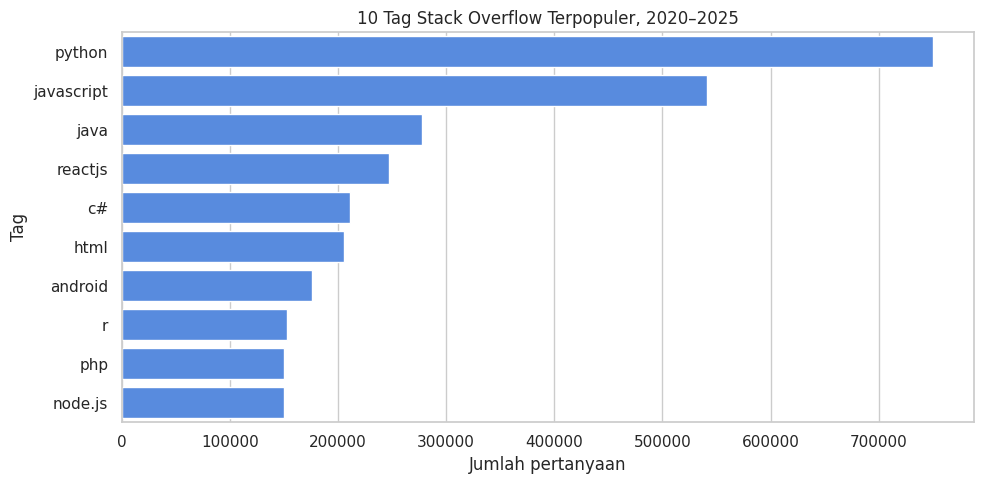

In [ ]:
import json
AUDIT_LOG.clear()
LAST_RESULTS.clear()
_ = get_top_tags(2020, 2025, 10)
top_tags_df = LAST_RESULTS["get_top_tags"].copy()
display(top_tags_df)

plt.figure(figsize=(10, 5))
sns.barplot(data=top_tags_df, x="question_count", y="tag", color="#4285F4")
plt.title("10 Tag Stack Overflow Terpopuler, 2020–2025")
plt.xlabel("Jumlah pertanyaan")
plt.ylabel("Tag")
plt.tight_layout()
plt.show()

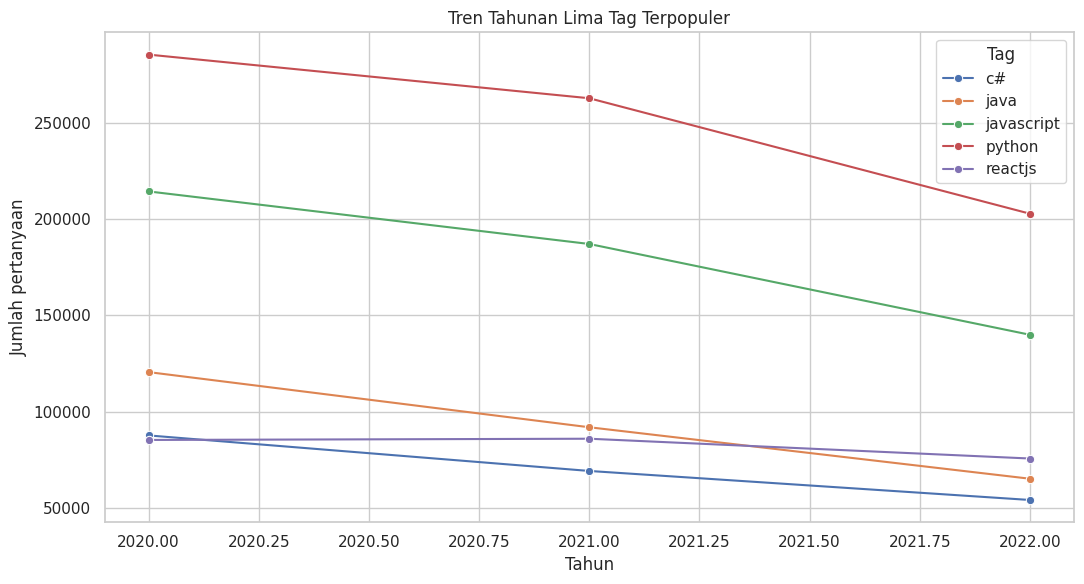

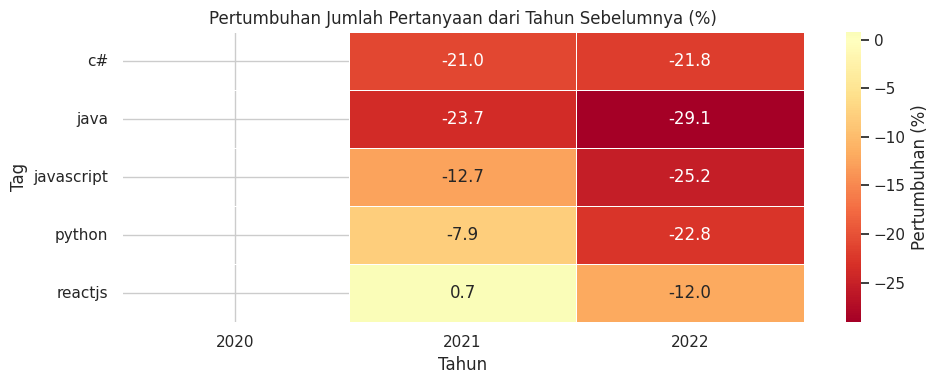

In [ ]:
selected_tags = top_tags_df.head(5)["tag"].tolist()

_ = compare_tags(selected_tags, 2020, 2025)
comparison_df = LAST_RESULTS["compare_tags"].copy()

# Line chart
plt.figure(figsize=(11, 6))

sns.lineplot(
    data=comparison_df,
    x="year",
    y="question_count",
    hue="tag",
    marker="o",
)

plt.title("Tren Tahunan Lima Tag Terpopuler")
plt.xlabel("Tahun")
plt.ylabel("Jumlah pertanyaan")
plt.legend(title="Tag")
plt.tight_layout()
plt.show()

# Membuat matriks tren
trend_matrix = (
    comparison_df
    .pivot(
        index="tag",
        columns="year",
        values="question_count",
    )
    .fillna(0)
    .astype(float)
)

# Menghitung pertumbuhan tahunan
growth_matrix = (
    trend_matrix
    .pct_change(axis=1, fill_method=None)
    .replace(
        [float("inf"), -float("inf")],
        float("nan"),
    )
    * 100
)

# Heatmap
plt.figure(figsize=(10, 4))

sns.heatmap(
    growth_matrix,
    annot=True,
    fmt=".1f",
    cmap="RdYlGn",
    center=0,
    linewidths=0.5,
    cbar_kws={"label": "Pertumbuhan (%)"},
)

plt.title("Pertumbuhan Jumlah Pertanyaan dari Tahun Sebelumnya (%)")
plt.xlabel("Tahun")
plt.ylabel("Tag")
plt.tight_layout()
plt.show()

,tag,question_count,answered_rate_pct,accepted_answer_rate_pct,avg_answers,avg_score,avg_views
0,python,750502,77.14,43.11,1.12,0.42,413.27
1,javascript,541108,76.42,42.35,1.15,0.45,435.28
2,java,277597,72.65,36.35,1.03,0.41,422.57
3,reactjs,246929,74.51,38.71,1.08,0.68,735.49
4,c#,211050,73.86,40.83,1.00,0.38,380.98


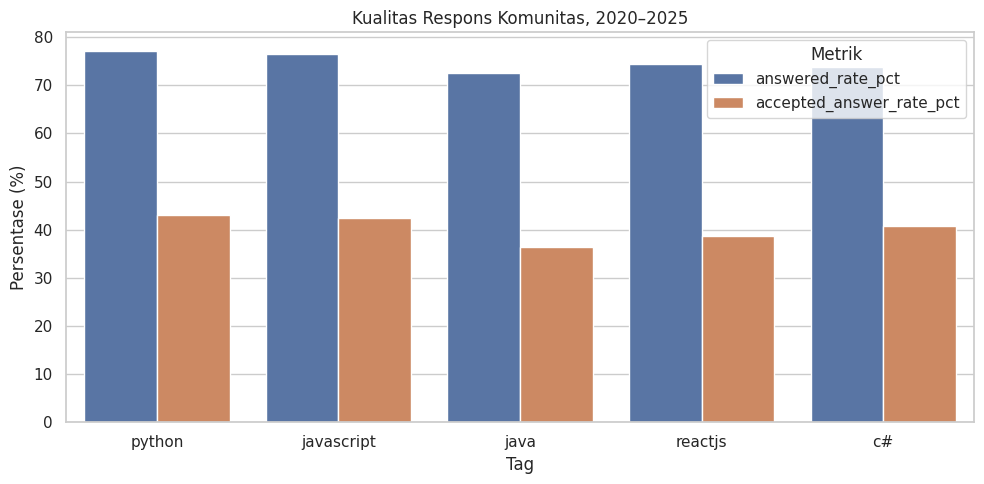

In [ ]:
_ = get_answer_rate(selected_tags, 2020, 2025)
answer_quality_df = LAST_RESULTS["get_answer_rate"].copy()
display(answer_quality_df)

quality_long = answer_quality_df.melt(
    id_vars="tag",
    value_vars=["answered_rate_pct", "accepted_answer_rate_pct"],
    var_name="metric", value_name="percent"
)
plt.figure(figsize=(10, 5))
sns.barplot(data=quality_long, x="tag", y="percent", hue="metric")
plt.title("Kualitas Respons Komunitas, 2020–2025")
plt.xlabel("Tag")
plt.ylabel("Persentase (%)")
plt.legend(title="Metrik")
plt.tight_layout()
plt.show()

## 9. Validasi silang dengan query manual
Bandingkan satu agregasi manual dengan nilai dari tool. Sel harus menghasilkan `True`.

In [ ]:
validation_tag = selected_tags[0]
validation_sql = f"""
SELECT COUNT(*) AS question_count
FROM `{DATASET_PREFIX}.posts_questions` AS q
WHERE q.creation_date >= TIMESTAMP(@start_date)
  AND q.creation_date < TIMESTAMP(@end_date)
  AND @tag IN UNNEST(SPLIT(q.tags, '|'))
"""
validation_parameters = [
    bigquery.ScalarQueryParameter("start_date", "DATE", date(2020, 1, 1)),
    bigquery.ScalarQueryParameter("end_date", "DATE", date(2026, 1, 1)),
    bigquery.ScalarQueryParameter("tag", "STRING", validation_tag),
]
manual_df = _run_safe_query(
    validation_sql, validation_parameters, "manual_validation", {"tag": validation_tag}
)
tool_value = int(top_tags_df.loc[top_tags_df["tag"] == validation_tag, "question_count"].iloc[0])
manual_value = int(manual_df["question_count"].iloc[0])
print({"tag": validation_tag, "tool_value": tool_value, "manual_value": manual_value})
assert tool_value == manual_value, "Hasil tool dan query manual berbeda."
print("Validasi silang berhasil: True")

{'tag': 'python', 'tool_value': 750502, 'manual_value': 750502}
Validasi silang berhasil: True


## 10. Pertanyaan interaktif dan ekspor hasil
Gunakan sel pertama untuk pertanyaan Anda. Sel kedua menyimpan tabel hasil sebagai CSV dan audit trail sebagai JSON agar mudah dimasukkan ke dokumentasi.

In [ ]:
user_question = input("Masukkan pertanyaan analitik: ").strip()
interactive_result = ask_agent(user_question)

Masukkan pertanyaan analitik: Mengapa n8n tidak cocok untuk data besar?


ClientError: 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'You exceeded your current quota, please check your plan and billing details. For more information on this error, head to: https://ai.google.dev/gemini-api/docs/rate-limits. To monitor your current usage, head to: https://ai.dev/rate-limit. \n* Quota exceeded for metric: generativelanguage.googleapis.com/generate_content_free_tier_requests, limit: 20, model: gemini-3.7-flash\nPlease retry in 36.709734825s.', 'status': 'RESOURCE_EXHAUSTED', 'details': [{'@type': 'type.googleapis.com/google.rpc.Help', 'links': [{'description': 'Learn more about Gemini API quotas', 'url': 'https://ai.google.dev/gemini-api/docs/rate-limits'}]}, {'@type': 'type.googleapis.com/google.rpc.QuotaFailure', 'violations': [{'quotaMetric': 'generativelanguage.googleapis.com/generate_content_free_tier_requests', 'quotaId': 'GenerateRequestsPerDayPerProjectPerModel-FreeTier', 'quotaDimensions': {'location': 'global', 'model': 'gemini-3.7-flash'},

In [ ]:
for result_name, result_df in LAST_RESULTS.items():
    filename = f"hasil_{result_name}.csv"
    result_df.to_csv(filename, index=False)
    print("Tersimpan:", filename)

with open("audit_trail.json", "w", encoding="utf-8") as file:
    json.dump(AUDIT_LOG, file, ensure_ascii=False, indent=2, default=str)
print("Tersimpan: audit_trail.json")

## 11. Checklist sebelum dikumpulkan

- [ ] Semua sel berjalan tanpa error dengan akun Anda.
- [ ] Audit trail menunjukkan minimal dua tool untuk prompt analisis kompleks.
- [ ] Hasil tool cocok dengan validasi SQL manual.
- [ ] Grafik dan angka aktual sudah dipindahkan ke `LAPORAN_TUGAS.md`.
- [ ] Kesimpulan tidak mengklaim sebab-akibat atau adopsi industri.
- [ ] Draf LinkedIn sudah diisi angka aktual dan tautan Colab.
- [ ] Jon Ruby Abdullah dan rubythalib.ai sudah disebut dalam posting.
- [ ] API key tidak terlihat pada notebook atau output.